# C-GAIMMD on a toy 1-D system

In an RFPS or TPS run, AIMMD picks its shooting points among the frames of
earlier paths. In **committor-conditioned Generative AIMMD (C-GAIMMD)**,
`chain_type='cgaimmd'`, the shooting points are *generated*: for every shot a
shooting worker draws a target committor $\lambda^*$, asks a **generator** for
configurations at that committor, checks and prepares them, and shoots from
the first one that passes the **final acceptance check**. Everything after the
shooting point (the two-way shot, registration, training, bins, reweighting)
is AIMMD's RFPS machinery, unchanged.

Two pieces do the work:

- the **network**, the committor model of the run: its `forward` gives the
  logit committor $\lambda(x)$ that every value pass, the adaptive bins and the
  reweighting use, exactly as for any AIMMD network;
- the **generator**, picked by name: here `'ode'`, which integrates the
  flow-matching velocity field $v(x_t, t \mid \lambda)$ that the network also
  carries, from a prior sample to a configuration at the requested
  $\lambda^*$. For proteins, `'bioemu2_edm'` uses BioEmu2's diffusion sampler
  instead (tutorials 5 and 6).

This notebook runs a small but complete C-GAIMMD campaign on the toy engine
with the minimal flow-matching network `TinyFlowNetwork`, on the CPU, in
about a minute. The sections:

1. the toy system and a C-GAIMMD params file;
2. seeds: end-state frames only (no initial transition is needed) and an
   initial network;
3. loading the params, the generator and the target-committor law;
4. the preflight, the check a job runs before it spends compute time;
5. the tasks of a run, one after the other: free simulations, shots under
   the bootstrap rule, a training round, shots under the target rule;
6. the per-shot sidecar and the shot table;
7. what the round learned, and target against final committor values;
8. a generator of your own, registered in about ten lines;
9. where to go from here.

## 0. Imports and a working folder

Everything is created in a fresh temporary folder, so the notebook is
self-contained and repeatable. Every C-GAIMMD device setting below is
`'cpu'`, so nothing touches a GPU.

In [1]:
import glob
import json
import os
import subprocess
import sys
import tempfile
import warnings

warnings.filterwarnings("ignore", category=UserWarning)          # MDAnalysis guesses
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm without widgets

import aimmd
import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
import torch
from aimmd.cgaimmd.flow_matching.toy import TinyFlowNetwork

work = tempfile.mkdtemp(prefix="cgaimmd_tutorial_")
os.chdir(work)
print("working in a fresh temporary folder")

working in a fresh temporary folder


## 1. The toy system and the params file

The toy engine moves one atom with $x \in [0, 10)$ by 100 random steps of
0.02 Å per frame, with $x = y = z$. The states: **A** is $x < 1$ or
$x > 9$, the reactive region **R** is $1 \le x < 2$ and **B** is
$2 \le x < 3$ (everything else is labelled `S` and never matters here).

A C-GAIMMD params file is an ordinary AIMMD params file with a few more
fields:

| field | value here | what it does |
|---|---|---|
| `chain_type` | `'cgaimmd'` | shooting points are generated, not selected |
| `initial_paths` | one file per basin | **end-state frames only**: C-GAIMMD needs no initial transition; the files seed the free simulations |
| `initial_network` | `'initial_network.h5'` | the weights every training round starts from (in production: a network pretrained on unbiased end-state MD) |
| `cgaimmd_generator` | `{'method': 'ode', ...}` | how candidates are generated: the method name and its settings |
| `cgaimmd_parameters` | a dict | the settings of the shooting loop (below) |
| `descriptors_function` | flat Å coordinates | under C-GAIMMD the descriptors are the coordinates of the atoms the generator generates, `(n_frames, 3 M)` |
| `network` | `Network()` | an instance of a class **defined in the params file** (a subclass is enough), because AIMMD's saved params file imports it from there |
| `cgaimmd_validity_function` | a function | checks every generated sample; here it keeps samples inside R |
| `fit` | `flow_matching_fit(...)` | the trainer's fit, with this run's keywords |

`round_shooting_index` and `masses_from_topology` are set in every C-GAIMMD
params file (the toy engine ignores the masses).

The `cgaimmd_parameters` used here, all others at their defaults:

| key | value | meaning |
|---|---|---|
| `lambda_window` | `(-2, 2)` | the target committors $\lambda^*$ (logits) are drawn uniformly in this window (the default law `'uniform'`) |
| `lambda_tolerance` | `1.0` | the **final acceptance check**: a candidate is shot only if $\lvert\lambda - \lambda^*\rvert \le 1$ ... |
| `window_after_trained_shots` | `4` | ... once the network was trained on 4 shooting points; before that any frame in R is accepted (the bootstrap rule). Production uses the default, 1000 |
| `lambda_clip` | `10.0` | the network's conditioning range $L$ (`TinyFlowNetwork` has none of its own) |
| `n_targets` | `8` | targets per pool refill (2 candidates each, the default `candidates_per_target`) |
| `placement` | `'none'` | the toy network generates absolute coordinates; molecular systems are placed in the box or re-solvated |
| `max_refills`, `wait_seconds` | `3`, `1.0` | after 3 refills without an acceptable candidate the worker waits 1 s and tries again |
| `generation_seed` | `0` | seeds of the generation streams (default: derived from the run folder) |
| `*_device` | `'cpu'` | where the network generates, evaluates and trains |

The fit trains for 1,500 steps per round (the default is 4,000), with a
larger learning rate than the default and no warm-up, so that the tiny
network learns something in one short round. It takes the generator's labels
again from the round's own committor every 500 steps (`relabel_every`).

In [2]:
PARAMS = '''
"""C-GAIMMD on the 1-D toy system (tutorial 3)."""
import numpy as np

from aimmd.cgaimmd.flow_matching.fit import flow_matching_fit
from aimmd.cgaimmd.flow_matching.toy import TinyFlowNetwork
from aimmd.cgaimmd.preparation.descriptors import coordinates_descriptors
from aimmd.cgaimmd.types import ValidityResult

engine = 'toy'
chain_type = 'cgaimmd'
states = 'ARB'
initial_paths = ['initial_A.xtc', 'initial_B.xtc']   # end-state frames, one file per basin
initial_network = 'initial_network.h5'
round_shooting_index = True
masses_from_topology = True
gen_temperature = 300.0

cgaimmd_generator = {'method': 'ode', 'sampler': 'midpoint', 'n_steps': 8, 'chunk': 16}
cgaimmd_parameters = {
    'lambda_window': (-2.0, 2.0),
    'lambda_tolerance': 1.0,
    'window_after_trained_shots': 4,
    'lambda_clip': 10.0,
    'n_targets': 8,
    'placement': 'none',
    'max_refills': 3,
    'wait_seconds': 1.0,
    'generation_seed': 0,
    'generation_device': 'cpu',
    'values_device': 'cpu',
    'training_device': 'cpu',
}


def toy_mdrun(ts):
    for _ in range(100):
        ts.positions = (ts.positions + .02 * np.random.normal()) % 10


def states_function(trajectory):
    x = np.array([frame.positions[0, 0] for frame in trajectory])
    labels = np.full(len(x), 'S', dtype='<U1')
    labels[(x < 1) | (x > 9)] = 'A'
    labels[(x >= 1) & (x < 2)] = 'R'
    labels[(x >= 2) & (x < 3)] = 'B'
    return labels


def descriptors_function(trajectory):
    return coordinates_descriptors(trajectory)       # (n_frames, 3): x, y, z of the atom


class Network(TinyFlowNetwork):
    pass


network = Network()


def cgaimmd_validity_function(positions, context):
    """Keep the generated samples inside R; the reason code is the text before the colon."""
    x = positions[:, 0, 0]
    ok = (x >= 1.0) & (x < 2.0)
    reason = np.array(['' if keep else f'outside_R: x = {xi:.2f}' for keep, xi in zip(ok, x)],
                      dtype=object)
    return ValidityResult(positions=positions, ok=ok, reason=reason)


def fit(params, pathensemble, verbose=False, worker=None):
    return flow_matching_fit(params, pathensemble, verbose=verbose, worker=worker,
                             steps_per_round=1500, relabel_every=500, lr=3e-3,
                             warmup_steps=0)
'''
with open("params.py", "w") as handle:
    handle.write(PARAMS.lstrip())
print("wrote params.py")

wrote params.py


## 2. Seeds: end-state frames and an initial network

One short file per basin, close to the reactive region (A just below
$x = 1$, B just above $x = 2$), so that the free simulations soon make
excursions into R. The initial network is a seeded, untrained
`TinyFlowNetwork`. In a real campaign it is a network pretrained on unbiased
MD of the two end states (`aimmd.cgaimmd.flow_matching.pretrain` for PaiNN,
`aimmd.cgaimmd.bioemu2.pretrain` for BioEmu2), and **every training round
starts again from it**: a round never continues from the previous round's
weights.

In [3]:
universe = mda.Universe.empty(1, trajectory=True)
for kind, x in (("A", 0.9), ("B", 2.1)):
    with mda.Writer(f"initial_{kind}.xtc", 1) as writer:
        for xi in x + 0.03 * np.sin(np.arange(10)):
            universe.atoms.positions = np.full((1, 3), xi, dtype=np.float32)
            writer.write(universe.atoms)
torch.manual_seed(0)
torch.save(TinyFlowNetwork().state_dict(), "initial_network.h5")
print(sorted(os.listdir(".")))

['initial_A.xtc', 'initial_B.xtc', 'initial_network.h5', 'params.py']


## 3. Load the params: the settings, the generator, the target law

Loading checks the C-GAIMMD rules: the network follows the committor
protocol, the generator can use the network, the descriptors have the width
$3M$ of the network's $M$ atoms, the initial paths hold frames of both end
states, and so on. Each initial path without a transition gets one line: it
seeds free simulations only.

`params.cgaimmd_settings` is `cgaimmd_parameters` with the defaults filled
in. The generator is built from `cgaimmd_generator` by
`aimmd.cgaimmd.generation.make_generator`; its `check(network)` lists what
the method needs from the network and does not find (nothing, here). A
generator turns a batch of target logits, shape `(B,)`, into candidates of
shape `(B, M, 3)` in Ångström.

In [4]:
from aimmd.cgaimmd.generation import available_generators, check_generator, make_generator

np.random.seed(0)
torch.manual_seed(0)
params = aimmd.Params.load("params.py", save=False)
settings = params.cgaimmd_settings
print("chain_type :", params.chain_type)
print("network    :", type(params.network).__name__, "generating", params.network.n_atoms, "atom")
for key in ("lambda_law", "lambda_window", "acceptance", "lambda_tolerance",
            "window_after_trained_shots", "n_targets", "candidates_per_target", "placement"):
    print(f"  {key:27s} {settings[key]!r}")

generator = make_generator(params.cgaimmd_generator, params.network)
print("\nknown generation methods:", available_generators())
print("generator:", generator.method, generator.settings())
print("problems :", check_generator(generator, params.network))
samples = generator.generate(params.network, torch.tensor([-1.0, 0.0, 1.0]),
                             generator=torch.Generator().manual_seed(0))
print("three candidates, shape", tuple(samples.shape), "x =", samples[:, 0, 0].numpy().round(3))

C-GAIMMD: initial path 'initial_A.xtc' has no 'ARB' transition; it seeds free simulations only
C-GAIMMD: initial path 'initial_B.xtc' has no 'ARB' transition; it seeds free simulations only
chain_type : cgaimmd
network    : Network generating 1 atom
  lambda_law                  'uniform'
  lambda_window               (-2.0, 2.0)
  acceptance                  'target'
  lambda_tolerance            1.0
  window_after_trained_shots  4
  n_targets                   8
  candidates_per_target       2
  placement                   'none'

known generation methods: ['bioemu2_edm', 'ode']
generator: ode {'sampler': 'midpoint', 'n_steps': 8, 'chunk': 16, 'guidance_scale': 1.0}
problems : []


three candidates, shape (3, 1, 3) x = [1.962 1.671 1.621]


## 4. The preflight

`python -m aimmd.cgaimmd.preflight params.py` runs, in a scratch folder,
what a job would run first: it loads the params, checks the files they name
and that `initial_network` loads, checks the fit's keywords without training,
builds and checks the generator, generates one candidate and takes it through
the validity function and the preparation, and checks GROMACS and a PLUMED
bias when the run has them. It prints one line per check and exits with
status 1 when a check fails, so a job script can run it as its first step
(`Launcher.create_job(..., preflight=True)`).

Here the untrained generator's one candidate may land outside R; that is a
warning, not a failure.

In [5]:
result = subprocess.run([sys.executable, "-m", "aimmd.cgaimmd.preflight", "params.py"],
                        capture_output=True, text=True)
print(result.stdout.replace(work + os.sep, ""))      # paths shown relative to the folder
print("exit status:", result.returncode)

C-GAIMMD: initial path 'initial_A.xtc' has no 'ARB' transition; it seeds free simulations only
C-GAIMMD: initial path 'initial_B.xtc' has no 'ARB' transition; it seeds free simulations only
C-GAIMMD preflight of params.py
OK       params: loaded (chain_type 'cgaimmd', engine 'toy')
OK       files: the 2 initial paths exist
OK       initial_network: initial_network.h5 loads into Network
OK       fit: the flow-matching fit with steps_per_round=1500, relabel_every=500, lr=0.003, warmup_steps=0 (every round starts from initial_network)
OK       generator: 'ode' {'sampler': 'midpoint', 'n_steps': 8, 'chunk': 16, 'guidance_scale': 1.0} for Network with 1 atoms on cpu
OK       numerics: descriptors 3 wide, finite values and one tiny generation ({'n_atoms': 1, 'n_frames': 4, 'device': 'cpu', 'forward_range': [0.0, 0.0], 'committor_max_abs_diff': None, 'generation': {'method': 'ode', 'settings': {'sam...)
OK       configuration: lambda window (-2, 2), acceptance 'target' after 4 trained shots
O

## 5. Run the tasks one after the other

A production campaign starts all workers at once, locally with the Launcher
(`aimmd.Launcher("params.py", "run").run(n, n1, n2)`) or on a cluster with a
job script (`Launcher.create_job`). Running the tasks one after the other
with `aimmd.Worker` makes each step visible. The workers write their logs to
files in the run folder.

1. **The initial network** becomes the run's network file `run/networkARB.h5`
   (the Launcher and the trainer do this themselves before anything else).
2. **Free simulations** in both basins, seeded from the per-basin files:
   they give the in-state frames the fit needs and the exit statistics of the
   reweighting.
3. **Four shots under the bootstrap rule.** The network has not been trained
   on any shooting point yet, so any candidate in R is accepted, whatever its
   committor.
4. **A training round** on the four shots: the flow-matching fit trains the
   committor and the generator together, starting from `initial_network`,
   and the trainer saves the result with `networkARB.json`, which records
   the round and the number of trained shooting points.
5. **Four more shots.** Four trained shots reach `window_after_trained_shots`:
   the final check now enforces $\lvert\lambda - \lambda^*\rvert \le 1$.

In [6]:
from aimmd.worker.utils import write_initial_network

RUN = os.path.abspath("run")
print("1. initial network:", write_initial_network(params, RUN))

for state in "AB":
    os.makedirs(f"{RUN}/free{state}", exist_ok=True)
    aimmd.Worker(params, RUN, nframes=40, walltime=60,
                 log_file=f"free{state}/worker0.log").free(state, 0, 1)
free = sorted(os.path.relpath(f, RUN) for f in glob.glob(f"{RUN}/free*/traj*.xtc"))
print("2. free trajectories:", free)

os.makedirs(f"{RUN}/chainR0", exist_ok=True)
aimmd.Worker(params, RUN, nsteps=4, walltime=120, log_file="chainR0/worker.log").shoot(1, 0)
print("3. shots:", sorted(os.path.basename(f) for f in glob.glob(f"{RUN}/chainR0/path*.xtc")))

Writing initial network /tmp/cgaimmd_tutorial_k8rufzqt/initial_network.h5 to /tmp/cgaimmd_tutorial_k8rufzqt/run/networkARB.h5


1. initial network: written


2. free trajectories: ['freeA/traj000001.part0000.xtc', 'freeA/traj000001.part0001.xtc', 'freeA/traj000002.part0000.xtc', 'freeA/traj000002.part0001.xtc', 'freeB/traj000001.part0000.xtc', 'freeB/traj000001.part0001.xtc']


3. shots: ['path000001.xtc', 'path000002.xtc', 'path000003.xtc', 'path000004.xtc']


In [7]:
aimmd.Worker(params, RUN, walltime=120, log_file="trainARB.log").train(nrounds=1)
metadata = json.load(open(f"{RUN}/networkARB.json"))
print("4. networkARB.json:", {key: metadata[key] for key in ("round", "n_trained_shots", "status")})

aimmd.Worker(params, RUN, nsteps=8, walltime=180, log_file="chainR0/worker.log").shoot(1, 0)
print("5. shots:", sorted(os.path.basename(f) for f in glob.glob(f"{RUN}/chainR0/path*.xtc")))

4. networkARB.json: {'round': 1, 'n_trained_shots': 4, 'status': 'trained'}


5. shots: ['path000001.xtc', 'path000002.xtc', 'path000003.xtc', 'path000004.xtc', 'path000005.xtc', 'path000006.xtc', 'path000007.xtc', 'path000008.xtc']


The shooting worker's log tells the same story in its own words: one line
per pool refill (how many candidates were generated, how many passed the
validity function, and why the others did not) and one line per shooting
point (target, final committor, rule, candidates tried).

In [8]:
with open(f"{RUN}/chainR0/worker.log") as handle:
    for line in handle:
        if line.startswith(("C-GAIMMD", "WARNING")):
            print(line.rstrip().replace(RUN + os.sep, "run/"))

C-GAIMMD pool refill 1 for run/chainR0/path000001: 16 candidates for 8 targets (network 0ea134b1, uniform); 16 passed stage 1 (none) in 0.00 s
C-GAIMMD shooting point for run/chainR0/path000001: lambda*=1.371 lambda=0.000 (bootstrap_any_R), 1 candidates tried (none), network 0ea134b1, 0.01 s
C-GAIMMD shooting point for run/chainR0/path000002: lambda*=-0.424 lambda=0.000 (bootstrap_any_R), 1 candidates tried (none), network 0ea134b1, 0.00 s
C-GAIMMD shooting point for run/chainR0/path000003: lambda*=1.076 lambda=0.000 (bootstrap_any_R), 1 candidates tried (none), network 0ea134b1, 0.00 s
C-GAIMMD shooting point for run/chainR0/path000004: lambda*=-1.077 lambda=0.000 (bootstrap_any_R), 1 candidates tried (none), network 0ea134b1, 0.00 s
C-GAIMMD pool refill 1 for run/chainR0/path000005: 16 candidates for 8 targets (network 457dbfd1, uniform); 7 passed stage 1 (outside_R: 9) in 0.00 s
C-GAIMMD shooting point for run/chainR0/path000005: lambda*=-0.687 lambda=0.174 (target), 3 candidates tr

## 6. The per-shot sidecar and the shot table

Every C-GAIMMD shot has a **sidecar**, `chainR0/path<n>.xtc.cgaimmd.json`. The
reweighting reads nothing from it: generated shots are book-kept exactly
like RFPS shots. The sidecar records how the shooting point was made, so
that the law of the generated shooting points can be studied later: the
target, raw and final committor values, the acceptance rule, the network
that generated it, the generator's method and settings, the pool and the
seeds, the rejected candidates, the preparation records, the cost, and the
software versions. Here is part of the sidecar of the first shot under the
target rule:

In [9]:
from aimmd.cgaimmd.sidecar import read_shot_sidecar

paths = sorted(glob.glob(f"{RUN}/chainR0/path??????.xtc"))
records = [read_shot_sidecar(path) for path in paths]
record = next(r for r in records if r["acceptance"]["rule"] == "target")
shown = {key: record[key] for key in ("schema", "source", "path", "lambda_target", "lambda_raw",
                                      "lambda_final", "lambda_registered", "state_final",
                                      "acceptance", "generator", "candidates", "cost_seconds")}
shown["network"] = {key: record["network"][key] for key in ("round", "n_trained_shots",
                                                             "metadata_matched")}
print(json.dumps(shown, indent=1))
print("\nall keys:", ", ".join(record))

{
 "schema": "aimmd.cgaimmd.shot/1",
 "source": "cgaimmd",
 "path": "path000005.xtc",
 "lambda_target": -0.6870836391300497,
 "lambda_raw": 0.17098289728164673,
 "lambda_final": 0.17420774698257446,
 "lambda_registered": 0.17098283767700195,
 "state_final": "R",
 "acceptance": {
  "enforced": true,
  "n_trained_shots": 4,
  "rule": "target",
  "tolerance": 1.0,
  "window": [
   -2.0,
   2.0
  ],
  "window_after_trained_shots": 4
 },
 "generator": {
  "batch_size": 16,
  "method": "ode",
  "settings": {
   "chunk": 16,
   "guidance_scale": 1.0,
   "n_steps": 8,
   "sampler": "midpoint"
  }
 },
 "candidates": {
  "rejected": {
   "lambda_window": 2
  },
  "tried": 3
 },
 "cost_seconds": {
  "final_check": 0.0017223889008164406,
  "generate": 0.002720894291996956,
  "minimize": 0.0,
  "prepare": 2.5781337171792984e-05,
  "raw_lambda": 0.0003685560077428818,
  "total": 0.007633274886757135,
  "validity": 0.0001219138503074646
 },
 "network": {
  "round": 1,
  "n_trained_shots": 4,
  "metad

`aimmd.cgaimmd.sidecar.shot_table` turns the sidecars and state caches of a
run folder into one row per shot, and `summarise_shots` counts them. Both only
read: nothing is written into the run folder.

In [10]:
from aimmd.cgaimmd.sidecar import shot_table, summarise_shots

rows = shot_table(RUN, params=params)
print(f"{'path':15s} {'ends':5s} {'rule':16s} {'lambda*':>8s} {'lambda':>8s} {'tried':>5s}  rejected")
for row in rows:
    print(f"{row['path']:15s} {row['first_state']}{row['last_state']:4s} "
          f"{row['acceptance_rule']:16s} {row['lambda_target']:+8.2f} {row['lambda_final']:+8.2f} "
          f"{row['candidates_tried']:5d}  {row['candidates_rejected']}")
summary = summarise_shots(rows)
print("\nreactive shots:", summary["n_reactive"], "of", summary["n_shots"],
      "| acceptance rules:", summary["acceptance_rules"],
      "| rejected at the final check:", summary["candidates_rejected"])

path            ends  rule              lambda*   lambda tried  rejected
path000001.xtc  BA    bootstrap_any_R     +1.37    +0.00     1  {}
path000002.xtc  AB    bootstrap_any_R     -0.42    +0.00     1  {}
path000003.xtc  AB    bootstrap_any_R     +1.08    +0.00     1  {}
path000004.xtc  AA    bootstrap_any_R     -1.08    +0.00     1  {}
path000005.xtc  BA    target              -0.69    +0.17     3  {'lambda_window': 2}
path000006.xtc  AA    target              +0.73    +0.17     2  {'lambda_window': 1}
path000007.xtc  AB    target              -0.69    +0.01     1  {}
path000008.xtc  AB    target              +0.73    +0.31     1  {}

reactive shots: 6 of 8 | acceptance rules: {'bootstrap_any_R': 4, 'target': 4} | rejected at the final check: {'lambda_window': 3}


## 7. What the round learned, and target against final committor

The left panel shows the committor (logit, toward B) of the initial and of
the trained network along $x$: the round, trained on the four bootstrap shots
and the free-simulation frames, turned the flat initial committor into one
that rises from A to B. The right panel puts every shot's target $\lambda^*$
against the committor $\lambda$ of the frame that was shot. Bootstrap shots
are accepted at any $\lambda$; target-rule shots must lie in the tolerance
band around the diagonal, and candidates outside it were rejected (the
`rejected` column above).

One round on four shots teaches the generator little, so the final values
stay near the middle while the targets spread over the window. With a
production budget (thousands of fit steps per round, hundreds of shots) the
points close in on the diagonal: that is how C-GAIMMD places shooting points
at chosen committor levels.

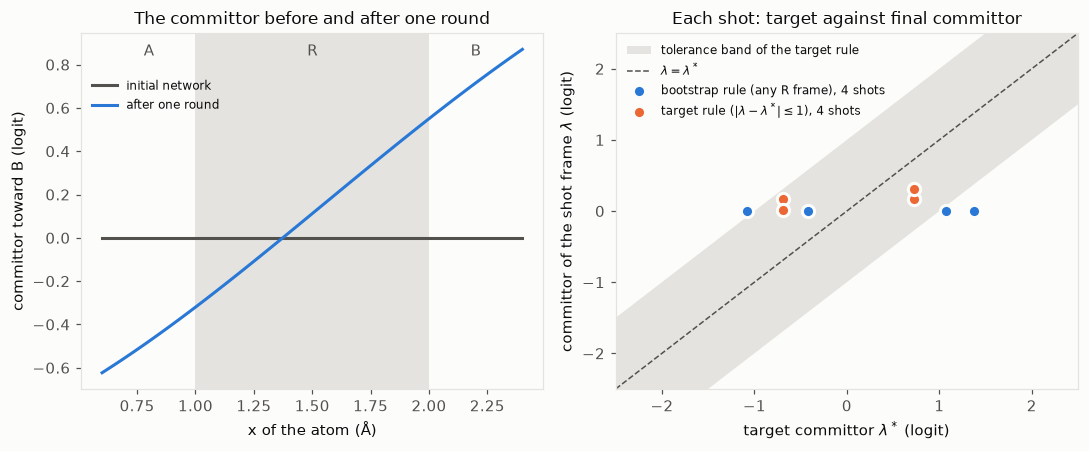

In [11]:
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"

x = np.linspace(0.6, 2.4, 91)
inputs = torch.tensor(np.repeat(x[:, None], 3, axis=1), dtype=torch.float32)
network = TinyFlowNetwork()
curves = {}
for label, fname in (("initial network", "initial_network.h5"),
                     ("after one round", f"{RUN}/networkARB.h5")):
    network.load_state_dict(torch.load(fname, weights_only=True))
    with torch.no_grad():
        curves[label] = network(inputs).numpy().ravel()

target = np.array([r["lambda_target"] for r in records])
final = np.array([r["lambda_final"] for r in records])
rules = np.array([r["acceptance"]["rule"] for r in records])
tolerance = settings["lambda_tolerance"]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.2), dpi=110)
fig.patch.set_facecolor(SURFACE)
for ax in (left, right):
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED)
    for spine in ax.spines.values():
        spine.set_color(GRID)

left.axvspan(1.0, 2.0, color=GRID, linewidth=0)
for name, xpos in (("A", 0.8), ("R", 1.5), ("B", 2.2)):
    left.text(xpos, 0.97, name, transform=left.get_xaxis_transform(), ha="center", va="top",
              color=MUTED)
for (label, values), color in zip(curves.items(), (MUTED, BLUE)):
    left.plot(x, values, color=color, linewidth=2, label=label)
left.set_xlabel("x of the atom (Å)", color=INK)
left.set_ylabel("committor toward B (logit)", color=INK)
left.set_title("The committor before and after one round", color=INK, fontsize=11)
left.legend(loc="upper left", bbox_to_anchor=(0.0, 0.9), fontsize=8, frameon=False,
            labelcolor=INK)

grid = np.linspace(-2.5, 2.5, 2)
right.fill_between(grid, grid - tolerance, grid + tolerance, color=GRID, linewidth=0,
                   label="tolerance band of the target rule")
right.plot(grid, grid, color=MUTED, linewidth=1, linestyle="--", label=r"$\lambda = \lambda^*$")
for rule, color, label in (("bootstrap_any_R", BLUE, "bootstrap rule (any R frame)"),
                           ("target", ORANGE, r"target rule ($|\lambda - \lambda^*| \leq 1$)")):
    mask = rules == rule
    right.scatter(target[mask], final[mask], s=64, color=color, edgecolor=SURFACE,
                  linewidth=2, zorder=3, label=f"{label}, {mask.sum()} shots")
right.set_xlim(-2.5, 2.5)
right.set_ylim(-2.5, 2.5)
right.set_xlabel(r"target committor $\lambda^*$ (logit)", color=INK)
right.set_ylabel(r"committor of the shot frame $\lambda$ (logit)", color=INK)
right.set_title("Each shot: target against final committor", color=INK, fontsize=11)
right.legend(loc="upper left", fontsize=8, frameon=False, labelcolor=INK)
fig.tight_layout()
plt.show()

The flow-matching fit keeps its bookkeeping next to the network:
`flow_fitARB/state.json` (the round counter, the held-out chains) and one
record per round in `flow_fitARB/rounds.jsonl`. `networkARB.json` holds the
metadata of the network file the shooting workers load: the round, where it
started from, the seed, the keywords of the fit.

In [12]:
with open(f"{RUN}/flow_fitARB/rounds.jsonl") as handle:
    for line in handle:
        r = json.loads(line)
        print(f"round {r['round']}: {r['status']}, shooting points {r['data']['n_sp']}, "
              f"relabels within the round {r['relabels_in_round']}")
print("start of every round:", metadata["start"]["kind"],
      os.path.basename(metadata["start"]["file"]))
print("fit keywords:", metadata["keywords"], "| seed:", metadata["seed"])

round 1: trained, shooting points 4, relabels within the round 2
start of every round: initial_network initial_network.h5
fit keywords: {'lr': 0.003, 'relabel_every': 500, 'steps_per_round': 1500, 'warmup_steps': 0} | seed: 0


## 8. A generator of your own

A generator is any object with a `method` name and three methods: `check`,
`generate` and `settings`. It is registered under its name with
`register_generator`, in the params file or in a module the params file
imports, so that every worker that loads the params registers it too. Here is
a deliberately simple one: it ignores the requested committor and returns
positions spread uniformly between `low` and `high`, a baseline that shoots
from random points in R.

In [13]:
CUSTOM = '''

# --- a generator of our own ---
import torch
from aimmd.cgaimmd.generation import register_generator


class UniformInR:
    """Ignores the target committor: x uniform in [low, high) (a baseline)."""
    method = 'uniform_in_R'

    def __init__(self, low=1.0, high=2.0):
        self.low, self.high = float(low), float(high)

    def check(self, network):
        return [] if network.n_atoms == 1 else ['uniform_in_R generates one atom']

    def generate(self, network, lam, *, generator=None):
        x = self.low + (self.high - self.low) * torch.rand(len(lam), generator=generator)
        return x[:, None, None].repeat(1, 1, 3)            # (B, 1, 3) in Angstrom, x == y == z

    def settings(self):
        return {'low': self.low, 'high': self.high}


register_generator('uniform_in_R', UniformInR)
cgaimmd_generator = {'method': 'uniform_in_R', 'low': 1.2, 'high': 1.8}
'''
with open("params_custom.py", "w") as handle:
    handle.write(PARAMS.lstrip() + CUSTOM)

result = subprocess.run([sys.executable, "-m", "aimmd.cgaimmd.preflight", "params_custom.py"],
                        capture_output=True, text=True)
for line in result.stdout.splitlines():
    if line.startswith(("OK       generator", "OK       candidate", "WARNING", "FAIL", "preflight")):
        print(line.replace(work + os.sep, ""))

OK       generator: 'uniform_in_R' {'low': 1.2, 'high': 1.8} for Network with 1 atoms on cpu
OK       candidate: 1 of 1 valid, generated in 0.0 s; prepared in 0.0 s; final check passed (state R, lambda 0 for a target of 0)
preflight OK: 9 checks


The custom generator runs through the same shooting loop. Two shots in a
run folder of their own; the sidecars record the method and its settings.

In [14]:
custom = aimmd.Params.load("params_custom.py", save=False)
RUN_CUSTOM = os.path.abspath("run_custom")
write_initial_network(custom, RUN_CUSTOM)
os.makedirs(f"{RUN_CUSTOM}/chainR0", exist_ok=True)
aimmd.Worker(custom, RUN_CUSTOM, nsteps=2, walltime=120, log_file="chainR0/worker.log").shoot(1, 0)
for path in sorted(glob.glob(f"{RUN_CUSTOM}/chainR0/path??????.xtc")):
    r = read_shot_sidecar(path)
    print(os.path.basename(path), "| generator:", r["generator"]["method"],
          r["generator"]["settings"], "| x of the shooting point:",
          round(np.load(path + ".descriptors.npy")[r["registration"]["shooting_index"], 0], 2))

C-GAIMMD: initial path 'initial_A.xtc' has no 'ARB' transition; it seeds free simulations only
C-GAIMMD: initial path 'initial_B.xtc' has no 'ARB' transition; it seeds free simulations only
Writing initial network /tmp/cgaimmd_tutorial_k8rufzqt/initial_network.h5 to /tmp/cgaimmd_tutorial_k8rufzqt/run_custom/networkARB.h5


path000001.xtc | generator: uniform_in_R {'high': 1.8, 'low': 1.2} | x of the shooting point: 1.56
path000002.xtc | generator: uniform_in_R {'high': 1.8, 'low': 1.2} | x of the shooting point: 1.36


## 9. Where to go from here

- **The Launcher.** The same campaign with every worker at once, in a fresh
  run folder: `aimmd.Launcher("params.py", "run_launcher").run(1, 1, 1,
  nsteps=8, walltime=300)`. The trainer then runs rounds continuously, and
  each new network resets the shooting worker's candidate pool.
- **The C-GAIMMD user guide** explains the generation interface, the
  settings, the final acceptance check and the sidecars in full;
  **Running production campaigns** covers installs, preflight, job scripts,
  restarts and backups; **Troubleshooting** lists the start-up messages and
  their fixes.
- **Molecular systems.** Tutorial 4 runs PaiNN C-GAIMMD on alanine
  dipeptide (NANMA) with GROMACS; tutorials 5 and 6 run BioEmu2 C-GAIMMD on
  chignolin and on trypsin with benzamidine.